# Forecasting the Oil Futures Term Structure
**Financial Econometrics group coursework | Imperial College Business School**

**Goal.** Forecast next month's change in the oil calendar spread, (CL2 − CL1) / CL1, using LASSO on monthly data. Test the forecast out of sample against a random walk, check the model with diagnostics, and turn the forecast into a simple calendar-spread trading rule. The reader is a trader who is not an econometrician, so every step below says in plain words what it does and why.

Settings that come from the team's Decision Log are marked DECIDED, PROPOSED or OPEN where they appear. The PROPOSED and OPEN ones run on a placeholder so the notebook works; change them in Step 1.2 and re-run.

Run the cells top to bottom. All settings live in one place (Step 1.2), so changing a decision means changing one line.

---
## Step 1: Setup and loading

We load the tools, set every project parameter in one place, and read the three monthly sheets from `Oil Data.xlsx`. The daily and weekly sheets are not used for modelling **[DECIDED: monthly only]**.

### 1.1 Imports and display settings
Standard Python libraries: `pandas` for tables, `statsmodels` for the statistical tests, `scikit-learn` for LASSO, `matplotlib` for charts.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import (
    acorr_breusch_godfrey, acorr_ljungbox, het_breuschpagan, het_arch,
)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, LassoCV, LinearRegression
from sklearn.model_selection import TimeSeriesSplit
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

### 1.2 Project settings (the one place to change a decision)
Every choice from the Decision Log is a variable here. Nothing later in the notebook has these numbers typed in.

In [2]:
DATA_PATH = "Oil Data.xlsx"

# ---- Data -----------------------------------------------------------------
# [DECIDED] individual oil-company stocks are removed (they repeat the oil & gas index;
#           Shell is also missing 127 months).
COMPANY_STOCKS = ["ExxonMobil", "ConocoPhilips", "Chevron", "BP", "Shell", "TotalEnergies"]
# [PROPOSED] Total Open Interest is exactly Commercial Long + Commercial Short, so it adds nothing.
DROP_OTHER = ["Total Open Interest"]

# ---- Split and windows ----------------------------------------------------
# Each row of the model data is a forecast ORIGIN: the month-end when we make the forecast.
# [DECIDED] train 1995-2014, test Jan 2015 - May 2024 (113 forecast origins).
TRAIN_END  = "2014-12"   # last origin in the initial training sample
TEST_START = "2015-01"   # first forecast origin
TEST_END   = "2024-05"   # last forecast origin (its target month is Jun 2024)
# [OPEN] expanding vs rolling: we run both. [DECIDED] rolling length = 120 months.
ROLLING_N  = 120
MAIN_WINDOW = "expanding"        # current plan: expanding is the main case, rolling the check

# ---- LASSO tuning ---------------------------------------------------------
# [OPEN] number of time-series cross-validation folds and the rule for picking the penalty.
N_CV_SPLITS = 5
PENALTY_GRID = np.logspace(-7, -1, 60)   # penalties tried; the target is a fraction (0.02 = 2%), so they are small
LASSO_RULE  = "min"              # "min" = penalty with the lowest CV error; "1se" = sparser choice

# ---- Robustness: "without COVID" -----------------------------------------
# [PROPOSED] exclude forecasts by TARGET month (the month being forecast).
COVID_MAIN = ["2020-03", "2020-04", "2020-05"]
COVID_WIDE = [f"2020-{m:02d}" for m in range(1, 13)]

# ---- Diagnostics ----------------------------------------------------------
# [PROPOSED] Chow-test break dates; 2005 was spotted in the descriptive statistics.
CHOW_BREAKS = ["2005-01", "2015-01"]
LAGS_DIAG = 12                   # lags used in autocorrelation tests

# ---- Trading --------------------------------------------------------------
# [PROPOSED] sign rule; threshold, size and costs are still to be drilled down.
TRANSACTION_COST = 0.0           # $ per barrel each time the position changes (placeholder)

### 1.3 Load the three monthly sheets
`Industry_M` holds the CL1 and CL2 futures prices and the industry series, `Macro_M` the macro series, and `StockPrices_M` the stock-market series. We strip stray spaces from the column names (for example `Brent `), and create a `month` key because the sheets use different date conventions: `Macro_M` uses calendar month-ends, the others use the last trading day of the month. Joining on year and month avoids a mismatch.

In [3]:
def load_sheet(name):
    d = pd.read_excel(DATA_PATH, sheet_name=name)
    d.columns = d.columns.str.strip()
    d["month"] = pd.to_datetime(d["Date"]).dt.to_period("M")
    return d.drop(columns="Date")

industry = load_sheet("Industry_M")
macro    = load_sheet("Macro_M")
stocks   = load_sheet("StockPrices_M")

---
## Step 2: Cleaning and the target

We join the sheets, remove the series we decided not to use, and build the thing we are forecasting.

### 2.1 Join the sheets and sort oldest-first
The Excel sheets list the newest month first. We sort ascending so that "previous month" and "next month" mean what they say. (The monthly CL1 and CL2 were checked against the daily sheet: they equal the last daily price of each month, so the monthly data is month-end data.)

In [4]:
df = (industry.merge(macro, on="month").merge(stocks, on="month")
              .set_index("month").sort_index())

### 2.2 Remove series we decided not to use
- **Individual oil-company stocks** are removed **[DECIDED]**: they overlap with the Dow Jones oil & gas index, and Shell is missing 127 months.
- **Total Open Interest** is dropped **[PROPOSED]** because it is exactly Commercial Long + Commercial Short (checked), so it adds nothing.

In [5]:
df = df.drop(columns=COMPANY_STOCKS + DROP_OTHER)

### 2.3 Build the target: the calendar spread and its next-month change
- `spread` = (CL2 − CL1) / CL1. Positive means contango (the second month costs more), negative means backwardation.
- `y` = **next month's change in the spread**, spread(t+1) − spread(t). This is what we forecast **[DECIDED: lead with the change]**. We keep the level form alongside: the forecast level is today's spread plus the forecast change.
- `dollar_spread` = CL2 − CL1 in dollars per barrel, and `dspread_change` its next-month change. This is for the trading step, where profit is measured in dollars per barrel.

The last month (Jun 2024) has no "next month", so `y` is empty there. That is expected.

In [6]:
df["spread"]         = (df["CL2"] - df["CL1"]) / df["CL1"]
df["y"]              = df["spread"].shift(-1) - df["spread"]          # change in spread, t -> t+1
df["dollar_spread"]  = df["CL2"] - df["CL1"]
df["dspread_change"] = df["dollar_spread"].shift(-1) - df["dollar_spread"]

---
## Step 3: A first look at the target

Before modelling, we look at what the spread actually does. This is also where the regime change that motivates a rolling window shows up.

### 3.1 The spread and its monthly change
Top: the spread level in percent. Bottom: the month-to-month change we are trying to forecast. The grey band marks Mar to May 2020.

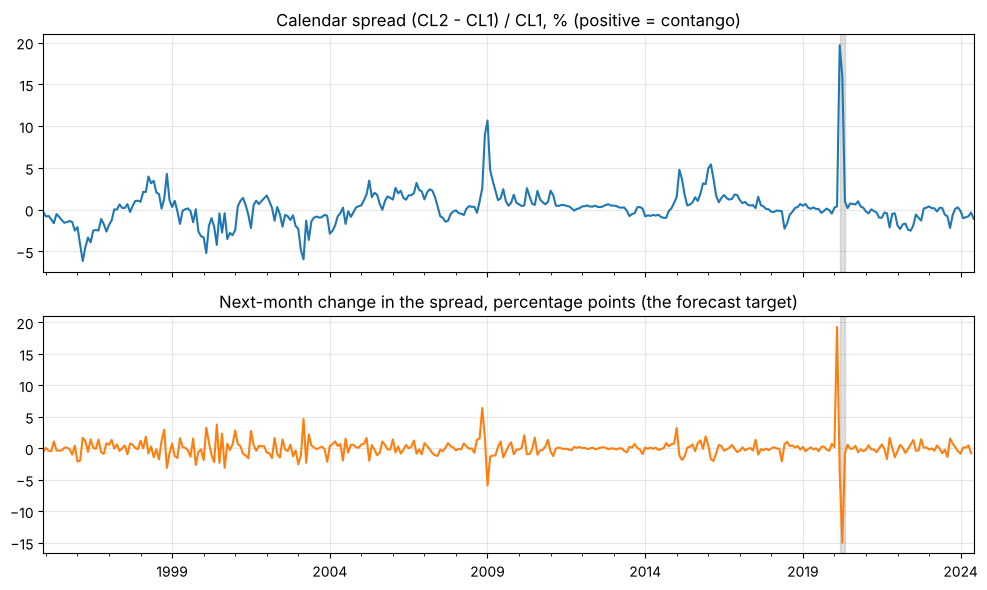

In [7]:
def ts(obj):
    # PeriodIndex -> Timestamp index, so matplotlib can draw dates and shaded bands
    o = obj.copy()
    o.index = o.index.to_timestamp()
    return o

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ts(df["spread"] * 100).plot(ax=ax[0], color="tab:blue")
ax[0].set_title("Calendar spread (CL2 - CL1) / CL1, % (positive = contango)")
ts(df["y"] * 100).plot(ax=ax[1], color="tab:orange")
ax[1].set_title("Next-month change in the spread, percentage points (the forecast target)")
for a in ax:
    a.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-05-31"), color="grey", alpha=0.25)
    a.set_xlabel("")
plt.tight_layout(); plt.show()

### 3.2 Has the spread changed character over time?
We split the sample into three decades. `mean reversion` is the slope from regressing the next change on today's spread: a negative number means a high spread tends to fall back. The average level flips sign between the first and second decade, and the pull-back is strongest recently. That is the case for testing a rolling window.

In [8]:
rows = []
for a, b in [("1995", "2004"), ("2005", "2014"), ("2015", "2024")]:
    sub = df.loc[a:b, ["spread", "y"]].dropna()
    slope = np.polyfit(sub["spread"], sub["y"], 1)[0]
    rows.append({"period": f"{a}-{b}", "months": len(sub),
                 "mean spread %": sub["spread"].mean() * 100,
                 "std of spread %": sub["spread"].std() * 100,
                 "mean reversion slope": slope})
print(pd.DataFrame(rows).set_index("period"))

full = df[["spread", "y"]].dropna()
print(f"\nFull sample: mean {full.spread.mean()*100:.2f}%, std {full.spread.std()*100:.2f}%, "
      f"lag-1 autocorrelation of the spread {df['spread'].autocorr(1):.2f}")

           months  mean spread %  std of spread %  mean reversion slope
period                                                                 
1995-2004     120        -0.8477           1.8963               -0.2569
2005-2014     120         0.8995           1.6104               -0.2193
2015-2024     113         0.5869           2.7246               -0.4063

Full sample: mean 0.20%, std 2.24%, lag-1 autocorrelation of the spread 0.71


### 3.3 The COVID months
The spread jumped in March and April 2020 and snapped back in May. This is the evidence behind excluding March to May 2020 in the robustness check (Step 9). Dates: the OPEC+ breakdown on 6 Mar, the WHO pandemic declaration on 11 Mar, and WTI trading below zero on 20 Apr 2020.

In [9]:
print((df.loc["2020-01":"2020-08", ["CL1", "CL2", "spread"]]).assign(spread_pct=lambda d: d.spread * 100).drop(columns="spread"))

            CL1     CL2  spread_pct
month                              
2020-01 51.5600 51.6800      0.2327
2020-02 44.7600 44.9400      0.4021
2020-03 20.4800 24.5100     19.6777
2020-04 18.8400 21.8500     15.9766
2020-05 35.4900 35.8400      0.9862
2020-06 39.2700 39.3400      0.1783
2020-07 40.2700 40.5700      0.7450
2020-08 42.6100 42.9000      0.6806


---
## Step 4: Building the predictors

The 17 candidate series from the monthly sheets (after Step 2.2), plus today's spread, become the feature table. Two rules shape it:

1. **Timing.** A row is a forecast origin, the end of month *t*. It only uses information available at the end of month *t*, and its target is the change from *t* to *t+1*. This is what "lagged one month" means: the predictors always sit one month before the month being forecast.
2. **Publication delay.** CPI and industrial production are published weeks after the month ends, so for them we use the previous month's value, one extra month of lag.

### 4.1 Candidate list and how each is transformed
**[PROPOSED]** Many of these series trend upwards (prices, inventories, rig counts), so using their raw levels would mostly capture the trend. We use monthly percentage changes (`logdiff`) for those, plain changes (`diff`) for rates, and the series as it is (`level`) when it already is a change or a return. The tests in Step 5 will check whether this worked. Edit `TRANSFORM` to change the list; this table is where the team confirms the final 16 or 17.

In [10]:
# column -> (transformation, extra publication lag, plain-English description)
TRANSFORM = {
    "Brent":                      ("logdiff", 0, "Brent crude price"),
    "CRKS321C Index":             ("logdiff", 0, "3-2-1 refining crack spread"),
    "Baltic Dry Index":           ("logdiff", 0, "Shipping costs, a global-demand proxy"),
    "Daily Production":           ("logdiff", 0, "Daily oil output"),
    "Inventories":                ("logdiff", 0, "Crude and product stocks"),
    "Rig Count":                  ("logdiff", 0, "Active drilling rigs"),
    "Commercial Long":            ("logdiff", 0, "Commercial traders' long futures positions"),
    "Commercial Short":           ("logdiff", 0, "Commercial traders' short futures positions"),
    "CPI YOY %":                  ("diff",    1, "Inflation rate (change in the rate)"),
    "3M Yield":                   ("diff",    0, "3-month T-bill yield (change)"),
    "10Y Yield":                  ("diff",    0, "10-year Treasury yield (change)"),
    "IndustrialProduction Index": ("logdiff", 1, "Industrial output, a GDP proxy"),
    "SPX":                        ("logdiff", 0, "S&P 500"),
    "DXY returns":                ("level",   0, "US dollar index return (already a return)"),
    "VIX":                        ("diff",    0, "Equity volatility index (change)"),
    "Gasoline All Grades":        ("logdiff", 0, "Gasoline price"),
    "Dow Jones US Oil&Gas Index": ("logdiff", 0, "US oil & gas equity index"),
}
cand = pd.DataFrame(TRANSFORM, index=["transformation", "extra lag (months)", "what it is"]).T
cand.loc["Spread level"] = ["level", 0, "Today's spread; lets the model capture mean reversion"]
cand

,transformation,extra lag (months),what it is
Brent,logdiff,0,Brent crude price
CRKS321C Index,logdiff,0,3-2-1 refining crack spread
Baltic Dry Index,logdiff,0,"Shipping costs, a global-demand proxy"
Daily Production,logdiff,0,Daily oil output
Inventories,logdiff,0,Crude and product stocks
Rig Count,logdiff,0,Active drilling rigs
Commercial Long,logdiff,0,Commercial traders' long futures positions
Commercial Short,logdiff,0,Commercial traders' short futures positions
CPI YOY %,diff,1,Inflation rate (change in the rate)
3M Yield,diff,0,3-month T-bill yield (change)


### 4.2 Build the feature table
One function applies the transformations and publication lags. Percentage changes use logs, which is safe because all of these series are strictly positive.

In [11]:
def build_features(frame):
    X = pd.DataFrame(index=frame.index)
    for col, (how, extra_lag, _) in TRANSFORM.items():
        if how == "logdiff":
            s = np.log(frame[col]).diff()
        elif how == "diff":
            s = frame[col].diff()
        else:
            s = frame[col]
        X[col] = s.shift(extra_lag) if extra_lag else s
    X["Spread level"] = frame["spread"]
    return X

X = build_features(df)
FEATURES = list(X.columns)

### 4.3 Assemble the model data and count the forecast origins
We attach the target and drop incomplete rows. The first months are lost to differencing and the extra publication lag, and the last month has no target. We expect 352 usable forecast origins, Feb 1995 to May 2024.

In [12]:
data = X.join(df[["y", "dspread_change"]]).dropna()
assert len(data) == 352, "expected 352 origins (Feb 1995 to May 2024)"

### 4.4 First look: how each predictor relates to the target
A quick correlation of each feature with the next-month change, using the training years only so the test period stays untouched. **This is only a first look; it does not select anything.** LASSO makes the selection in Step 7, and the strongest simple correlation is usually today's spread (mean reversion).

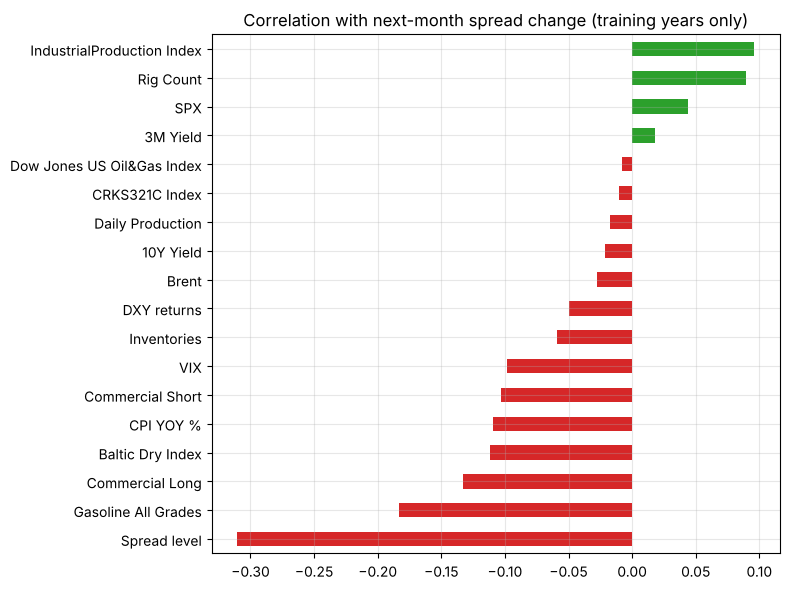

In [13]:
train_view = data.loc[:TRAIN_END]
corr = train_view[FEATURES].corrwith(train_view["y"]).sort_values()
ax = corr.plot.barh(figsize=(8, 6), color=np.where(corr > 0, "tab:green", "tab:red"))
ax.set_title("Correlation with next-month spread change (training years only)")
plt.tight_layout(); plt.show()

---
## Step 5: Stationarity tests (ADF and KPSS)

**Why.** A regression on a series that wanders without returning to an average (a unit root) can find relationships that are not there. We want the target and predictors to be stationary: stable average and spread over time.

**Two tests, opposite questions** **[PROPOSED shortlist]**:
- **ADF** assumes there *is* a unit root. A small p-value (below 0.05) is evidence the series is stationary.
- **KPSS** assumes the series *is* stationary. A small p-value is evidence it is not.

ADF has low power on persistent series like the spread, so we run both. If they agree we are confident; if they disagree we flag the series as unclear. We use the training years only.

### 5.1 Test helper
Runs both tests on one series and returns a one-line verdict.

In [14]:
def stationarity_row(series, name):
    s = series.dropna()
    adf_p = adfuller(s, autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]
    if adf_p < 0.05 and kpss_p >= 0.05:
        verdict = "stationary"
    elif adf_p >= 0.05 and kpss_p < 0.05:
        verdict = "unit root"
    else:
        verdict = "unclear"
    return {"series": name, "ADF p-value": adf_p, "KPSS p-value": kpss_p, "verdict": verdict}

### 5.2 The raw series (before any transformation)
This shows why we transform: raw prices and counts mostly fail.

In [15]:
raw_cols = [c for c in TRANSFORM if c != "DXY returns"] + ["spread"]
raw_tbl = pd.DataFrame([stationarity_row(df.loc[:TRAIN_END, c], c) for c in raw_cols]).set_index("series")
raw_tbl

,ADF p-value,KPSS p-value,verdict
series,,,
Brent,0.3782,0.0100,unit root
CRKS321C Index,0.1332,0.0100,unit root
Baltic Dry Index,0.2175,0.0744,unclear
Daily Production,0.9970,0.0614,unclear
Inventories,0.7455,0.0100,unit root
Rig Count,0.5031,0.0100,unit root
Commercial Long,0.8484,0.0100,unit root
Commercial Short,0.8515,0.0100,unit root
CPI YOY %,0.0437,0.1000,stationary


### 5.3 The series we actually use (after transformation)
The target `y` and every feature. Any "unit root" or "unclear" rows need discussion before we trust the model: the usual fix is a different transformation (see Step 4.1).

In [16]:
used_tbl = pd.DataFrame(
    [stationarity_row(train_view["y"], "y (target: change in spread)")]
    + [stationarity_row(train_view[c], c) for c in FEATURES]
).set_index("series")
used_tbl

,ADF p-value,KPSS p-value,verdict
series,,,
y (target: change in spread),0.0000,0.1000,stationary
Brent,0.0003,0.1000,stationary
CRKS321C Index,0.0000,0.0749,stationary
Baltic Dry Index,0.0000,0.1000,stationary
Daily Production,0.0000,0.0142,unclear
Inventories,0.0206,0.1000,stationary
Rig Count,0.0000,0.1000,stationary
Commercial Long,0.0000,0.1000,stationary
Commercial Short,0.0000,0.1000,stationary


---
## Step 6: Train/test split and the benchmark

### 6.1 The split **[DECIDED]**
- **Training sample:** forecast origins Feb 1995 to Dec 2014 (239 months).
- **Test sample:** 113 forecast origins, Jan 2015 to May 2024. An origin of Jan 2015 means the forecast is made at the end of January 2015 for February 2015, so the *target months* are Feb 2015 to Jun 2024.

A model is never evaluated on months it has seen: at each origin it is fitted only on earlier rows, so it uses 239 months for the first forecast. Whether those windows grow (expanding) or slide (rolling) is Step 7.

In [17]:
train_idx = data.loc[:TRAIN_END].index
test_idx  = data.loc[TEST_START:TEST_END].index
assert len(train_idx) == 239 and len(test_idx) == 113

### 6.2 The benchmark: random walk **[DECIDED]**
The random walk says the best guess for next month's spread is today's spread, so the **forecast change is zero**. The real spread still moves randomly around that guess; only the point forecast is zero. Any model has to beat this to be useful.

In [18]:
bench = pd.DataFrame({"actual_change": data.loc[test_idx, "y"], "random_walk_forecast": 0.0})
rw_rmse = np.sqrt((bench.actual_change ** 2).mean())
print(f"Random-walk RMSE over the test sample: {rw_rmse*100:.3f} percentage points")

Random-walk RMSE over the test sample: 2.449 percentage points


---
## Step 7: The models and the forecasting loop

### 7.1 The two models
- **LASSO [DECIDED].** A regression that shrinks coefficients and sets weak predictors exactly to zero, so it picks predictors automatically. Predictors are standardised first (so one penalty is fair across variables). The penalty strength is chosen by time-ordered cross-validation *inside the training window only*, so the test months never influence it.
- **OLS comparator [PROPOSED].** The plain regression on the same variables. It is easy to explain and shows what LASSO's shrinkage adds. (With 18 variables it is not tiny; a version using only the variables LASSO selected is an option.)

The tuning scheme (number of folds, penalty rule) is **[OPEN]**; see Step 1.2.

In [19]:
def one_se_alpha(cv_model):
    # Largest penalty whose CV error is within one standard error of the minimum
    mean_mse = cv_model.mse_path_.mean(axis=1)
    se = cv_model.mse_path_.std(axis=1) / np.sqrt(cv_model.mse_path_.shape[1])
    best = mean_mse.argmin()
    ok = mean_mse <= mean_mse[best] + se[best]
    return cv_model.alphas_[ok].max()

def lasso_fit_predict(X_train, y_train, x_new):
    scaler = StandardScaler().fit(X_train)            # scale using this window only
    Z = scaler.transform(X_train)
    cv = LassoCV(cv=TimeSeriesSplit(n_splits=N_CV_SPLITS), alphas=PENALTY_GRID,
                 max_iter=50000).fit(Z, y_train)
    alpha = cv.alpha_ if LASSO_RULE == "min" else one_se_alpha(cv)
    final = Lasso(alpha=alpha, max_iter=50000).fit(Z, y_train)
    return final.predict(scaler.transform(x_new))[0], alpha, final.coef_

def ols_fit_predict(X_train, y_train, x_new):
    return LinearRegression().fit(X_train, y_train).predict(x_new)[0]

### 7.2 The forecasting loop
For every test origin *t*:
1. Take the data available at *t*: expanding uses every earlier row, rolling uses only the latest `ROLLING_N` rows.
2. Fit LASSO (tuning the penalty inside that window) and OLS.
3. Forecast the change for the next month.
4. Store the forecast, the actual change, the LASSO penalty, and which predictors LASSO kept.

The row at origin *t* is only used for training from origin *t+1* onwards, because its target (the change to *t+1*) is only known then.

In [20]:
def run_forecasts(window, drop_months=()):
    # drop_months: target months to leave out of BOTH training and scoring (used in Step 9.2)
    rows, coefs = [], {}
    for t in test_idx:
        if str(t + 1) in drop_months:                 # no forecast for an excluded target month
            continue
        hist = data.loc[: t - 1]                      # rows whose target is already known at t
        if len(drop_months):
            hist = hist[~(hist.index + 1).astype(str).isin(drop_months)]   # keep them out of training too
        if window == "rolling":
            hist = hist.iloc[-ROLLING_N:]
        X_tr, y_tr = hist[FEATURES].values, hist["y"].values
        x_new = data.loc[[t], FEATURES].values

        p_las, alpha, coef = lasso_fit_predict(X_tr, y_tr, x_new)
        p_ols = ols_fit_predict(X_tr, y_tr, x_new)
        rows.append({"origin": t, "actual": data.loc[t, "y"], "rw": 0.0,
                     "ols": p_ols, "lasso": p_las, "alpha": alpha,
                     "n_selected": int((coef != 0).sum()), "n_train": len(hist)})
        coefs[t] = coef
    res = pd.DataFrame(rows).set_index("origin")
    res["target_month"] = res.index + 1
    res = res.join(data[["dspread_change"]])
    coef_df = pd.DataFrame(coefs, index=FEATURES).T   # standardised LASSO coefficients by origin
    return res, coef_df

### 7.3 Run both window types on the same 113 test months
Expanding and rolling are scored on exactly the same test origins, so they are directly comparable. This takes a minute or two (LASSO is tuned fresh at every origin).

In [21]:
results, coefs = {}, {}
for w in ["expanding", "rolling"]:
    results[w], coefs[w] = run_forecasts(w)

---
## Step 8: Evaluating the forecasts

**All metrics are out of sample**: they only use forecasts for months the model was not fitted on.

### 8.1 The metrics **[DECIDED: use all of them]**
- **RMSE:** the typical size of the forecast error (lower is better). It is the square root of the lecture's MSE, in the original units. We also show the random walk's RMSE.
- **MAE:** the average size of the error. Errors count in proportion to their size, not squared, so a few extreme months (such as spring 2020) weigh less than in RMSE. Comparing RMSE with MAE shows how much a result depends on extreme months.
- **MAPE** *(may be dropped after group discussion)*: the average error as a percentage of the actual change. It divides by the actual change, which is often close to zero (18 of the 113 test months move by less than 0.1 percentage points), so a few months can dominate it, and it is undefined when the change is exactly zero (those months are skipped). By construction the random walk scores 100%.
- **Out-of-sample R²:** 1 − (model's squared errors ÷ random walk's squared errors). Positive means the model beats the random walk; zero means no better; negative means worse.
- **Hit rate:** how often the forecast gets the *direction* of the change right (the thing the trade depends on). 50% is a coin flip.

In [22]:
def rmse(e):
    return float(np.sqrt(np.mean(np.square(e))))

def mae(e):
    return float(np.mean(np.abs(e)))

def mape(actual, e):
    keep = actual != 0               # undefined when the actual change is exactly zero
    return float(100 * np.mean(np.abs(e[keep] / actual[keep])))

def hit_rate(actual, forecast):
    m = (actual != 0) & (forecast != 0)
    return float((np.sign(actual[m]) == np.sign(forecast[m])).mean())

def evaluate(res, keep=None):
    r = res if keep is None else res[keep]
    a = r["actual"]
    out = {"random walk": {"RMSE (pp)": rmse(a) * 100, "MAE (pp)": mae(a) * 100, "MAPE %": mape(a, a),
                           "OOS R2 vs RW": 0.0, "hit rate": np.nan}}
    for m, label in [("ols", "OLS"), ("lasso", "LASSO")]:
        e = a - r[m]
        out[label] = {"RMSE (pp)": rmse(e) * 100, "MAE (pp)": mae(e) * 100, "MAPE %": mape(a, e),
                      "OOS R2 vs RW": 1 - (e ** 2).sum() / (a ** 2).sum(),
                      "hit rate": hit_rate(a, r[m])}
    return pd.DataFrame(out).T

### 8.2 Results for both windows (all 113 test origins)
RMSE and MAE are in percentage points of the spread (a value of 2.2 means a typical miss of 2.2 pp); MAPE is a percentage.

In [23]:
eval_all = {w: evaluate(results[w]) for w in results}
for w, tbl in eval_all.items():
    print(f"=== {w.upper()} window ===")
    print(tbl.to_string(), "\n")

=== EXPANDING window ===
             RMSE (pp)  MAE (pp)     MAPE %  OOS R2 vs RW  hit rate
random walk     2.4488    0.8647   100.0000        0.0000       NaN
OLS             2.3680    0.9479 1,717.3043        0.0649    0.5929
LASSO           2.3361    0.8186   616.5440        0.0899    0.6018 

=== ROLLING window ===
             RMSE (pp)  MAE (pp)   MAPE %  OOS R2 vs RW  hit rate
random walk     2.4488    0.8647 100.0000        0.0000       NaN
OLS             2.6781    1.1933 808.6253       -0.1960    0.5487
LASSO           2.3639    0.9056 240.4400        0.0681    0.4690 



### 8.3 Choosing between expanding and rolling **[OPEN]**
The plan: choose by a rule agreed *before* looking at results, so we are not picking whichever looks best afterwards. The rule below is a placeholder (**lowest LASSO RMSE**); change it if the team agrees something else. The cell prints what the rule would pick; it does not change `MAIN_WINDOW`.

In [24]:
rule_table = pd.Series({w: eval_all[w].loc["LASSO", "RMSE (pp)"] for w in eval_all}, name="LASSO RMSE (pp)")
print(rule_table.to_string())
print(f"\nRule picks: {rule_table.idxmin()}   |   MAIN_WINDOW currently set to: {MAIN_WINDOW}")

expanding   2.3361
rolling     2.3639

Rule picks: expanding   |   MAIN_WINDOW currently set to: expanding


### 8.4 Where did the model gain or lose against the random walk?
Cumulative sum of (random-walk squared error − model squared error) through time. The line rising means the model is beating the random walk in that stretch; falling means it is losing. This usually shows whether a gain is steady or comes from a few months.

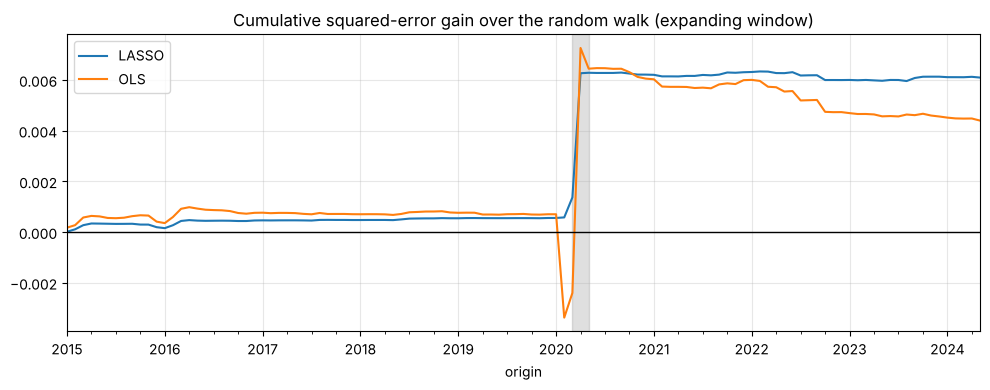

In [25]:
fig, ax = plt.subplots()
for m, label, c in [("lasso", "LASSO", "tab:blue"), ("ols", "OLS", "tab:orange")]:
    r = results[MAIN_WINDOW]
    gain = (r["actual"] ** 2 - (r["actual"] - r[m]) ** 2).cumsum()
    ts(gain).plot(ax=ax, label=label, color=c)
ax.axhline(0, color="black", lw=1)
ax.set_title(f"Cumulative squared-error gain over the random walk ({MAIN_WINDOW} window)")
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-05-31"), color="grey", alpha=0.25)
ax.legend(); plt.tight_layout(); plt.show()

### 8.5 Forecast versus actual (level form alongside the change)
The brief for the team is to lead with the change and report the level alongside. Level forecast = today's spread + forecast change.

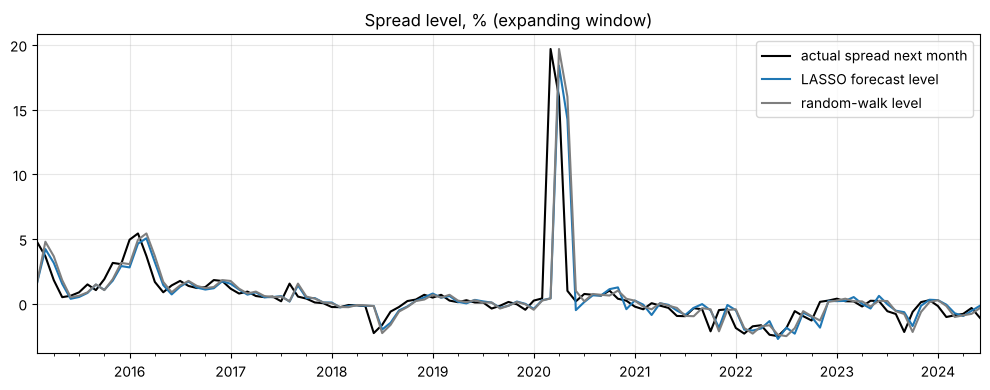

In [26]:
r = results[MAIN_WINDOW]
level = pd.DataFrame({
    "actual spread next month":  data.loc[r.index, "Spread level"] + r["actual"],
    "LASSO forecast level":      data.loc[r.index, "Spread level"] + r["lasso"],
    "random-walk level":         data.loc[r.index, "Spread level"],
}).set_axis(r["target_month"])
ts(level * 100).plot(figsize=(10, 4), color=["black", "tab:blue", "tab:grey"])
plt.title(f"Spread level, % ({MAIN_WINDOW} window)"); plt.xlabel(""); plt.tight_layout(); plt.show()

---
## Step 9: Robustness: what if the COVID shock had not happened? **[DECIDED]**

The spread jumped to about 20% in March 2020 against a typical 0.2%. A few huge errors can dominate RMSE, so we test how much of the result depends on those months. Exclusion is by **target month** (the month being forecast).

- **Main check [PROPOSED]:** remove target months Mar, Apr, May 2020 (forecast origins Feb, Mar, Apr 2020).
- **Wider check [PROPOSED]:** remove all of 2020.

The months were fixed from events and the spread's own spike, before looking at model results. We do this two ways, and they answer different questions.

### 9.1 Drop the COVID months from the scoring only (model unchanged)
The forecasts are the same as in Step 8; we just leave the excluded months out of the scorecard. This shows how much of the headline score comes from forecasting those months. The model has still learned from 2020 data in every later forecast, so it is not a clean test of a world without the shock.

In [27]:
def keep_mask(res, drop_months):
    return ~res["target_month"].astype(str).isin(drop_months)

blocks = {}
for w in results:
    for label, drop in [("all months", []), ("excl. Mar-May 2020", COVID_MAIN), ("excl. all 2020", COVID_WIDE)]:
        keep = keep_mask(results[w], drop)
        t = evaluate(results[w], keep)
        t.insert(0, "n", int(keep.sum()))
        blocks[(w, label)] = t
robust = pd.concat(blocks, names=["window", "sample"])
robust.loc[:, ["n", "RMSE (pp)", "MAE (pp)", "MAPE %", "OOS R2 vs RW", "hit rate"]]

n  RMSE (pp)  MAE (pp)     MAPE %  OOS R2 vs RW  hit rate
window    sample                                                                                     
expanding all months         random walk  113     2.4488    0.8647   100.0000        0.0000       NaN
                             OLS          113     2.3680    0.9479 1,717.3043        0.0649    0.5929
                             LASSO        113     2.3361    0.8186   616.5440        0.0899    0.6018
          excl. Mar-May 2020 random walk  110     0.7842    0.5431   100.0000        0.0000       NaN
                             OLS          110     0.9008    0.6681 1,762.0066       -0.3195    0.5909
                             LASSO        110     0.7614    0.5233   631.0535        0.0572    0.5909
          excl. all 2020     random walk  101     0.8057    0.5565   100.0000        0.0000       NaN
                             OLS          101     0.8669    0.6506 1,889.4360       -0.1576    0.5842
                             LASSO        101     0.7789    0.5324   676.6684        0.0654    0.5743
rolling   all months         random walk  113     2.4488    0.8647   100.0000        0.0000       NaN
                             OLS          113     2.6781    1.1933   808.6253       -0.1960    0.5487
                             LASSO        113     2.3639    0.9056   240.4400        0.0681    0.4690
          excl. Mar-May 2020 random walk  110     0.7842    0.5431   100.0000        0.0000       NaN
                             OLS          110     1.3968    0.9174   828.8160       -2.1729    0.5455
                             LASSO        110     0.8726    0.6045   244.3700       -0.2384    0.4727
          excl. all 2020     random walk  101     0.8057    0.5565   100.0000        0.0000       NaN
                             OLS          101     1.4095    0.9070   869.9516       -2.0604    0.5347
                             LASSO        101     0.8418    0.5778   240.4387       -0.0916    0.4851

### 9.2 Re-run the model in a world without the shock
Here the excluded months are removed from the training data as well as the scoring, and the whole forecasting loop is run again. The model never sees the COVID months, so this simulates a world where they did not happen. Because the training data changes, the forecasts change, and LASSO is re-tuned each time. Compare it with 9.1 to separate "the score depends on those months" from "those months changed what the model learned".

In [28]:
rerun_res, rerun_coefs, blocks2 = {}, {}, {}
for w in ["expanding", "rolling"]:
    for label, drop in [("excl. Mar-May 2020", COVID_MAIN), ("excl. all 2020", COVID_WIDE)]:
        res_x, coef_x = run_forecasts(w, drop_months=drop)
        rerun_res[(w, label)], rerun_coefs[(w, label)] = res_x, coef_x
        t = evaluate(res_x)
        t.insert(0, "n", len(res_x))
        blocks2[(w, label)] = t
robust_rerun = pd.concat(blocks2, names=["window", "sample"])
robust_rerun.loc[:, ["n", "RMSE (pp)", "MAE (pp)", "MAPE %", "OOS R2 vs RW", "hit rate"]]

n  RMSE (pp)  MAE (pp)     MAPE %  OOS R2 vs RW  hit rate
window    sample                                                                                     
expanding excl. Mar-May 2020 random walk  110     0.7842    0.5431   100.0000        0.0000       NaN
                             OLS          110     0.7741    0.5727 1,662.0585        0.0255    0.5636
                             LASSO        110     0.7435    0.5122   575.0113        0.1009    0.5909
          excl. all 2020     random walk  101     0.8057    0.5565   100.0000        0.0000       NaN
                             OLS          101     0.7785    0.5741 1,784.6483        0.0664    0.5743
                             LASSO        101     0.7657    0.5281   622.9641        0.0968    0.5842
rolling   excl. Mar-May 2020 random walk  110     0.7842    0.5431   100.0000        0.0000       NaN
                             OLS          110     0.8822    0.6185   546.9682       -0.2655    0.5455
                             LASSO        110     0.7286    0.5113   167.8451        0.1366    0.5455
          excl. all 2020     random walk  101     0.8057    0.5565   100.0000        0.0000       NaN
                             OLS          101     0.8248    0.6259   584.4374       -0.0480    0.5347
                             LASSO        101     0.7550    0.5260   181.9246        0.1218    0.4950

### 9.3 Does the shock change which predictors LASSO picks?
Share of forecast origins where LASSO keeps each variable (expanding window), with all months in the training data against the version that never saw Mar to May 2020. Large differences mean the shock changed what the model learned.

In [29]:
sel_compare = pd.DataFrame({
    "all months (%)": (coefs["expanding"] != 0).mean() * 100,
    "without Mar-May 2020 (%)": (rerun_coefs[("expanding", "excl. Mar-May 2020")] != 0).mean() * 100,
    "without all of 2020 (%)": (rerun_coefs[("expanding", "excl. all 2020")] != 0).mean() * 100,
}).sort_values("all months (%)", ascending=False)
sel_compare.loc["average number kept"] = [
    results["expanding"]["n_selected"].mean(),
    rerun_res[("expanding", "excl. Mar-May 2020")]["n_selected"].mean(),
    rerun_res[("expanding", "excl. all 2020")]["n_selected"].mean(),
]
sel_compare

,all months (%),without Mar-May 2020 (%),without all of 2020 (%)
Spread level,100.0000,100.0000,100.0000
Gasoline All Grades,73.4513,99.0909,98.0198
CPI YOY %,54.8673,13.6364,23.7624
3M Yield,45.1327,0.0000,0.0000
Dow Jones US Oil&Gas Index,44.2478,0.0000,0.0000
Rig Count,43.3628,0.0000,0.0000
VIX,15.9292,0.9091,0.9901
IndustrialProduction Index,1.7699,0.0000,0.0000
CRKS321C Index,0.0000,0.0000,0.0000
Brent,0.0000,0.0000,0.0000


---
## Step 10: Which predictors did LASSO choose?

After LASSO is fitted, we assess the predictors it has chosen **[DECIDED]**: which ones survive, their signs and sizes, whether they stay chosen across windows and over time, and whether that makes economic sense. This is how we explain *why* the model performs as it does, and the rolling-coefficient plot in 10.3 doubles as the parameter-stability chart.

Coefficients are on the standardised scale, so their sizes are comparable across predictors.

### 10.1 How often each predictor is selected
Share of the 113 forecast origins at which LASSO gave the variable a non-zero coefficient. Variables chosen nearly every time are the robust signals; those chosen rarely are noise or regime-specific.

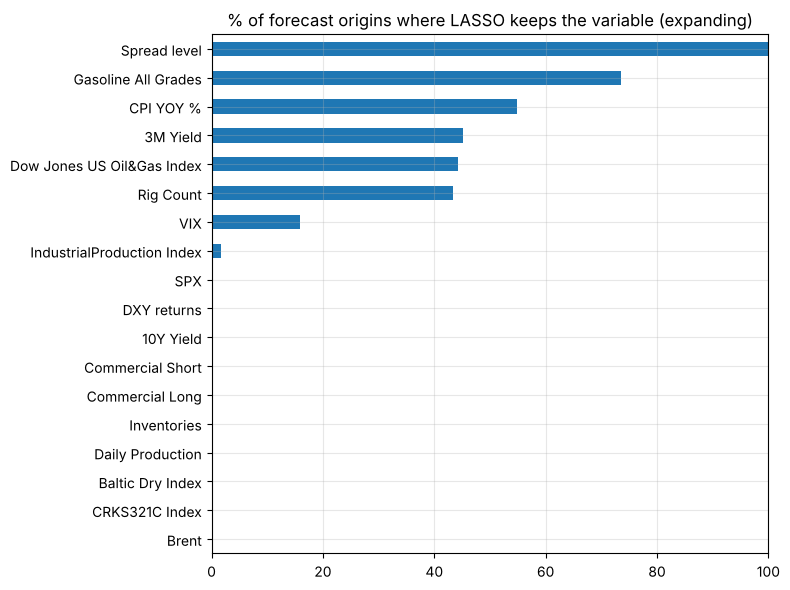

In [30]:
cdf = coefs[MAIN_WINDOW]
sel_freq = (cdf != 0).mean().sort_values()
ax = (sel_freq * 100).plot.barh(figsize=(8, 6), color="tab:blue")
ax.set_title(f"% of forecast origins where LASSO keeps the variable ({MAIN_WINDOW})")
ax.set_xlim(0, 100); plt.tight_layout(); plt.show()

### 10.2 Sign and size when selected
For each variable: how often it is chosen, its average coefficient when chosen, and how consistent the sign is.

In [31]:
nz = cdf.where(cdf != 0)
summary = pd.DataFrame({
    "selected %": sel_freq * 100,
    "avg coef when selected": nz.mean(),
    "share positive when selected": (nz > 0).sum() / nz.notna().sum(),
}).sort_values("selected %", ascending=False)
summary

,selected %,avg coef when selected,share positive when selected
Spread level,100.0000,-0.0036,0.0000
Gasoline All Grades,73.4513,-0.0007,0.0000
CPI YOY %,54.8673,-0.0004,0.0000
3M Yield,45.1327,-0.0019,0.0000
Dow Jones US Oil&Gas Index,44.2478,-0.0023,0.0000
Rig Count,43.3628,0.0008,1.0000
VIX,15.9292,0.0001,0.9444
IndustrialProduction Index,1.7699,0.0002,1.0000
10Y Yield,0.0000,NaN,NaN
Baltic Dry Index,0.0000,NaN,NaN


### 10.3 Do the coefficients drift over time? (parameter stability)
The coefficient of the most-often-selected variables at each forecast origin. A line that stays put means a stable relationship; one that wanders or flips sign points to a changing regime, which supports using a rolling window. The lower chart shows how many predictors LASSO keeps.

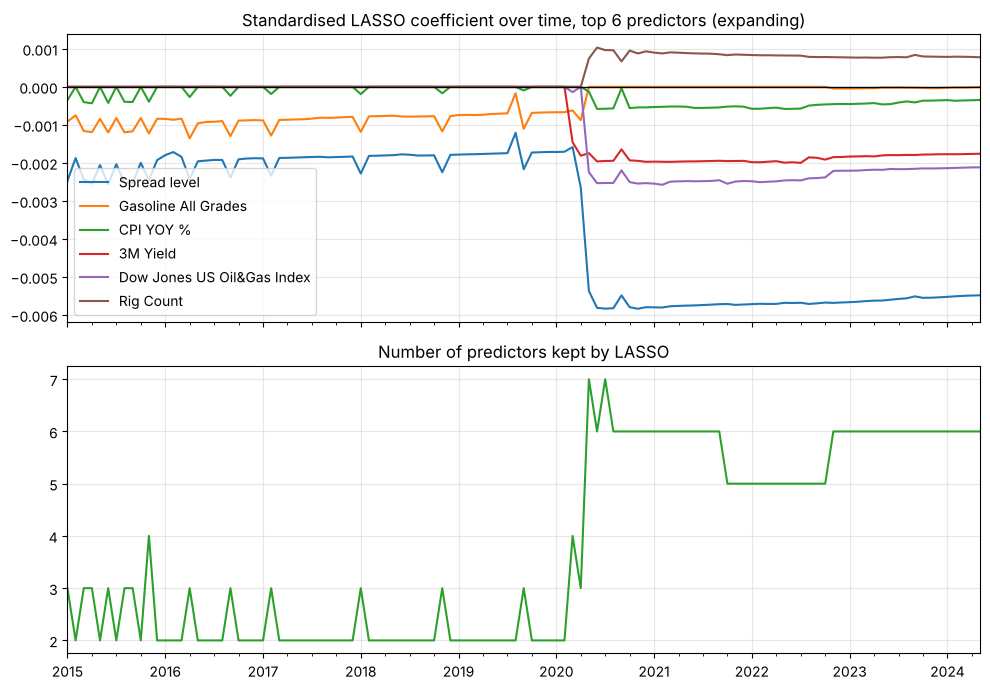

In [32]:
top = sel_freq.sort_values(ascending=False).head(6).index
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ts(cdf[top]).plot(ax=ax[0]); ax[0].axhline(0, color="black", lw=1)
ax[0].set_title(f"Standardised LASSO coefficient over time, top 6 predictors ({MAIN_WINDOW})")
ts(results[MAIN_WINDOW]["n_selected"]).plot(ax=ax[1], color="tab:green")
ax[1].set_title("Number of predictors kept by LASSO")
ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

### 10.4 Do the two windows agree?
If the same variables dominate under both windows, the findings are not an artefact of the window choice.

In [33]:
both = pd.DataFrame({w: (coefs[w] != 0).mean() * 100 for w in coefs}).sort_values("expanding", ascending=False)
both.columns = [f"selected % ({c})" for c in both.columns]
both

,selected % (expanding),selected % (rolling)
Spread level,100.0000,52.2124
Gasoline All Grades,73.4513,38.0531
CPI YOY %,54.8673,28.3186
3M Yield,45.1327,32.7434
Dow Jones US Oil&Gas Index,44.2478,26.5487
Rig Count,43.3628,22.1239
VIX,15.9292,34.5133
IndustrialProduction Index,1.7699,2.6549
CRKS321C Index,0.0000,15.9292
Brent,0.0000,23.8938


---
## Step 11: Diagnostics on the model

The brief asks whether the model satisfies basic econometric assumptions. Stationarity is done in Step 5; this step covers autocorrelation, heteroskedasticity and parameter stability, plus a supporting overlap check on the predictors.

**What is tested [DECIDED].** The standard tests need a fitted regression with residuals, and LASSO has no standard errors. So we test the model *as it ends up*: the predictors LASSO keeps at the **final forecast origin**, refitted by OLS ("post-LASSO OLS") on exactly the rows LASSO was trained on at that origin. The Ljung-Box and ARCH-LM checks also run on LASSO's actual out-of-sample forecast errors.

**Two versions.** 11.1 uses the expanding window (every row since 1995) and 11.2 the rolling window (the latest 120 months). Each has its own selected predictors. The Chow test runs on the expanding version only **[OPEN: to discuss with the team]**, because the break dates sit outside, or too close to the start of, the rolling sample.

**How to read the p-values.** Each test has a "no problem" starting assumption. A p-value below 0.05 means the data contradict it, and we flag a problem. If a test fails we report it and apply the standard fix: Newey-West standard errors for autocorrelation or heteroskedasticity, a rolling window or break dummy for instability. Because the predictors were chosen using the same data, the p-values are somewhat optimistic; this goes in the limitations.

The helper functions below are shared by 11.1 and 11.2, so the two windows are tested in exactly the same way.

In [34]:
diag = []   # one row per test, both windows

def add(window, area, test, run_on, p, if_flagged):
    diag.append({"window": window, "area": area, "test": test, "run on": run_on,
                 "p-value": p, "result": "flag" if p < 0.05 else "ok", "if flagged": if_flagged})

def post_lasso_model(window):
    # same training rows and same selected predictors as the LAST forecast of that window
    t_last = test_idx[-1]
    hist = data.loc[: t_last - 1]
    if window == "rolling":
        hist = hist.iloc[-ROLLING_N:]
    kept = [f for f, c in zip(FEATURES, coefs[window].loc[t_last]) if c != 0]
    if not kept:                      # LASSO kept nothing: its forecast is just the intercept
        return None, kept, hist
    fit = sm.OLS(hist["y"], sm.add_constant(hist[kept])).fit()
    return fit, kept, hist

def autocorr_tests(window, fit):
    if fit is not None:               # residual tests need a fitted regression
        bg = acorr_breusch_godfrey(fit, nlags=LAGS_DIAG)
        add(window, "Autocorrelation", "Breusch-Godfrey", "post-LASSO OLS residuals", bg[1],
            "model misses dynamics; use Newey-West errors")
    e = results[window]["actual"] - results[window]["lasso"]
    lb = acorr_ljungbox(e, lags=[LAGS_DIAG], return_df=True)
    add(window, "Autocorrelation", "Ljung-Box", "LASSO out-of-sample errors", float(lb["lb_pvalue"].iloc[0]),
        "forecasts leave a pattern; revisit predictors")

def hetero_tests(window, fit):
    if fit is not None:
        bp = het_breuschpagan(fit.resid, fit.model.exog)
        add(window, "Heteroskedasticity", "Breusch-Pagan", "post-LASSO OLS residuals", bp[1],
            "error size varies with predictors; use robust (HAC) errors")
        add(window, "Heteroskedasticity", "ARCH-LM", "post-LASSO OLS residuals", het_arch(fit.resid, nlags=6)[1],
            "volatility clusters; interpret risk with care")
    e = results[window]["actual"] - results[window]["lasso"]
    add(window, "Heteroskedasticity", "ARCH-LM", "LASSO out-of-sample errors", het_arch(e, nlags=6)[1],
        "volatility clusters; interpret risk with care")

def show(window, area):
    d = pd.DataFrame(diag)
    return d[(d["window"] == window) & (d["area"] == area)]

def vif_table(fit, kept):
    exog = fit.model.exog
    return pd.Series([variance_inflation_factor(exog, i) for i in range(1, exog.shape[1])],
                     index=kept, name="VIF").sort_values(ascending=False).to_frame()

def chow_test(X, y, break_month):
    Xc = sm.add_constant(X)
    k = Xc.shape[1]
    pre = X.index < pd.Period(break_month)
    ssr_all = sm.OLS(y, Xc).fit().ssr
    ssr_1 = sm.OLS(y[pre], Xc[pre]).fit().ssr
    ssr_2 = sm.OLS(y[~pre], Xc[~pre]).fit().ssr
    n = len(y)
    F = ((ssr_all - ssr_1 - ssr_2) / k) / ((ssr_1 + ssr_2) / (n - 2 * k))
    return F, 1 - stats.f.cdf(F, k, n - 2 * k), int(pre.sum()), int((~pre).sum())

## 11.1 Expanding-window diagnostics

### 11.1.1 The model being tested
The predictors LASSO keeps at the final origin (May 2024), refitted by OLS on every row available at that point. Coefficients are in the original units of each predictor, so they are not comparable in size across rows.

In [35]:
fit_exp, kept_exp, hist_exp = post_lasso_model("expanding")
print(f"{len(kept_exp)} predictors, fitted on {len(hist_exp)} months ({hist_exp.index[0]} to {hist_exp.index[-1]})")
fit_exp.params.to_frame("OLS coefficient")

6 predictors, fitted on 351 months (1995-02 to 2024-04)


,OLS coefficient
const,0.0010
Rig Count,0.0341
CPI YOY %,-0.0054
3M Yield,-0.0143
Gasoline All Grades,-0.0131
Dow Jones US Oil&Gas Index,-0.0470
Spread level,-0.3060


### 11.1.2 Autocorrelation: Breusch-Godfrey and Ljung-Box
- **Breusch-Godfrey** asks whether the OLS residuals are correlated with their own past (up to 12 lags). It is used instead of Durbin-Watson because that test is unreliable when a lagged value of the target (today's spread) is a regressor, which ours is. If the residuals are autocorrelated the model is missing some dynamics and the OLS standard errors cannot be trusted.
- **Ljung-Box** asks the same about LASSO's **out-of-sample forecast errors**. Autocorrelated errors mean the forecasts leave a predictable pattern behind.

In [36]:
autocorr_tests("expanding", fit_exp)
show("expanding", "Autocorrelation")

,window,area,test,run on,p-value,result,if flagged
0,expanding,Autocorrelation,Breusch-Godfrey,post-LASSO OLS residuals,0.0255,flag,model misses dynamics; use Newey-West errors
1,expanding,Autocorrelation,Ljung-Box,LASSO out-of-sample errors,0.0276,flag,forecasts leave a pattern; revisit predictors


### 11.1.3 Heteroskedasticity: Breusch-Pagan and ARCH-LM
- **Breusch-Pagan** asks whether the size of the errors depends on the predictors. It is chosen over White's test because White adds squares and cross-products, which is too many terms for our sample.
- **ARCH-LM** asks a different question: do large errors follow large errors (volatility clustering)? Oil volatility clusters (2008, 2020), which matters for the risk of the trading P&L. It runs on the OLS residuals and on LASSO's out-of-sample errors.

In [37]:
hetero_tests("expanding", fit_exp)
show("expanding", "Heteroskedasticity")

,window,area,test,run on,p-value,result,if flagged
2,expanding,Heteroskedasticity,Breusch-Pagan,post-LASSO OLS residuals,0.0000,flag,error size varies with predictors; use robust ...
3,expanding,Heteroskedasticity,ARCH-LM,post-LASSO OLS residuals,0.0207,flag,volatility clusters; interpret risk with care
4,expanding,Heteroskedasticity,ARCH-LM,LASSO out-of-sample errors,0.0046,flag,volatility clusters; interpret risk with care


### 11.1.4 Parameter stability: Chow test
The Chow test asks whether the regression coefficients are the same before and after a break date chosen in advance. We use two dates: **Jan 2005**, where the average spread flips from backwardation to contango, and **Jan 2015**, our train/test split. *The 2005 date was spotted in the descriptive statistics, so it is data-informed, and we say so in the report.* The rolling-coefficient chart in Step 10.3 is the companion visual, and it points to spring 2020 as the clearest break.

In [38]:
for b in CHOW_BREAKS:
    F, p, n1, n2 = chow_test(hist_exp[kept_exp], hist_exp["y"], b)
    add("expanding", "Parameter stability", f"Chow (break {b})", f"post-LASSO OLS ({n1} + {n2} obs)", p,
        "relationship changed; favours a rolling window")
show("expanding", "Parameter stability")

,window,area,test,run on,p-value,result,if flagged
5,expanding,Parameter stability,Chow (break 2005-01),post-LASSO OLS (119 + 232 obs),0.0004,flag,relationship changed; favours a rolling window
6,expanding,Parameter stability,Chow (break 2015-01),post-LASSO OLS (239 + 112 obs),0.0000,flag,relationship changed; favours a rolling window


### 11.1.5 Predictor overlap: VIF (supporting)
The variance inflation factor measures how much each predictor is explained by the others. Values above about 5 to 10 mean heavy overlap, which makes OLS coefficients unstable. Having only a few predictors left after LASSO should keep this low.

In [39]:
vif_table(fit_exp, kept_exp)

,VIF
Spread level,1.3250
Rig Count,1.3237
Dow Jones US Oil&Gas Index,1.1805
Gasoline All Grades,1.1701
CPI YOY %,1.1326
3M Yield,1.0285


## 11.2 Rolling-window diagnostics

The same tests on the rolling model: the predictors LASSO keeps at the final origin when it only sees the latest 120 months, refitted by OLS on those 120 rows. The Chow test is left out here **[OPEN]**. If LASSO keeps nothing at that origin there is no regression to test, and only the tests on its out-of-sample errors are run **[OPEN: see the team discussion on the rolling rule]**.

### 11.2.1 The model being tested

In [40]:
fit_rol, kept_rol, hist_rol = post_lasso_model("rolling")
print(f"{len(kept_rol)} predictors kept at the final origin; training window {hist_rol.index[0]} to {hist_rol.index[-1]} ({len(hist_rol)} months)")
if fit_rol is None:
    print("LASSO keeps no predictors in the latest 120 months, so its forecast there is just the constant. "
          "There is no regression to run the residual tests on; only the out-of-sample error tests below apply.")
    print(f"Origins in the rolling run with no predictors kept: {(results['rolling']['n_selected'] == 0).sum()} of {len(results['rolling'])}")
else:
    display(fit_rol.params.to_frame("OLS coefficient"))

0 predictors kept at the final origin; training window 2014-05 to 2024-04 (120 months)
LASSO keeps no predictors in the latest 120 months, so its forecast there is just the constant. There is no regression to run the residual tests on; only the out-of-sample error tests below apply.
Origins in the rolling run with no predictors kept: 45 of 113


### 11.2.2 Autocorrelation: Breusch-Godfrey and Ljung-Box

In [41]:
autocorr_tests("rolling", fit_rol)
show("rolling", "Autocorrelation")

,window,area,test,run on,p-value,result,if flagged
7,rolling,Autocorrelation,Ljung-Box,LASSO out-of-sample errors,0.0248,flag,forecasts leave a pattern; revisit predictors


### 11.2.3 Heteroskedasticity: Breusch-Pagan and ARCH-LM

In [42]:
hetero_tests("rolling", fit_rol)
show("rolling", "Heteroskedasticity")

,window,area,test,run on,p-value,result,if flagged
8,rolling,Heteroskedasticity,ARCH-LM,LASSO out-of-sample errors,0.0127,flag,volatility clusters; interpret risk with care


### 11.2.4 Predictor overlap: VIF (supporting)

In [43]:
if fit_rol is None:
    print("Not applicable: no predictors kept.")
else:
    display(vif_table(fit_rol, kept_rol))

Not applicable: no predictors kept.


## 11.3 All diagnostics in one table
This is the table to take into the report. `flag` means p < 0.05.

In [44]:
diag_table = pd.DataFrame(diag)
diag_table["p-value"] = diag_table["p-value"].map(lambda v: f"{v:.4f}")
diag_table

,window,area,test,run on,p-value,result,if flagged
0,expanding,Autocorrelation,Breusch-Godfrey,post-LASSO OLS residuals,0.0255,flag,model misses dynamics; use Newey-West errors
1,expanding,Autocorrelation,Ljung-Box,LASSO out-of-sample errors,0.0276,flag,forecasts leave a pattern; revisit predictors
2,expanding,Heteroskedasticity,Breusch-Pagan,post-LASSO OLS residuals,0.0000,flag,error size varies with predictors; use robust ...
3,expanding,Heteroskedasticity,ARCH-LM,post-LASSO OLS residuals,0.0207,flag,volatility clusters; interpret risk with care
4,expanding,Heteroskedasticity,ARCH-LM,LASSO out-of-sample errors,0.0046,flag,volatility clusters; interpret risk with care
5,expanding,Parameter stability,Chow (break 2005-01),post-LASSO OLS (119 + 232 obs),0.0004,flag,relationship changed; favours a rolling window
6,expanding,Parameter stability,Chow (break 2015-01),post-LASSO OLS (239 + 112 obs),0.0000,flag,relationship changed; favours a rolling window
7,rolling,Autocorrelation,Ljung-Box,LASSO out-of-sample errors,0.0248,flag,forecasts leave a pattern; revisit predictors
8,rolling,Heteroskedasticity,ARCH-LM,LASSO out-of-sample errors,0.0127,flag,volatility clusters; interpret risk with care


---
## Step 12: Trading rule and the strategy chart

### 12.1 The rule **[PROPOSED]**
A calendar-spread trade driven only by the *sign* of the forecast:
- **Forecast change > 0** (spread expected to widen toward contango): **buy CL2, sell CL1** (long the spread, position +1).
- **Forecast change < 0**: **sell CL2, buy CL1** (short the spread, position −1).

Profit each month = position × the actual change in the dollar spread (CL2 − CL1), in **dollars per barrel**. The threshold (only trade if the forecast is large enough), position size and costs are still to be drilled down, so the rule here is the simplest version: always in the market, one unit, costs set by `TRANSACTION_COST` (0 for now).

**What is the benchmark in the line chart? [OPEN]** The professor suggested a line chart of the strategy against the benchmark. A random-walk forecast never trades, so its profit is a flat line at zero. We also show an "always long the spread" line as a more informative comparison. The team should decide which one(s) go into the report.

In [45]:
def strategy_pnl(res, forecast_col, cost=TRANSACTION_COST):
    pos = np.sign(res[forecast_col])
    turnover = pos.diff().abs().fillna(pos.abs())
    return pos * res["dspread_change"] - cost * turnover

def perf(pnl):
    cum = pnl.cumsum()
    return {"total P&L ($/bbl)": pnl.sum(), "mean per month": pnl.mean(),
            "std per month": pnl.std(),
            "annualised Sharpe": pnl.mean() / pnl.std() * np.sqrt(12),
            "% months profitable": (pnl > 0).mean() * 100,
            "max drawdown ($/bbl)": (cum - cum.cummax()).min()}

r = results[MAIN_WINDOW]
pnls = pd.DataFrame({
    "LASSO strategy": strategy_pnl(r, "lasso"),
    "OLS strategy": strategy_pnl(r, "ols"),
    "Always long the spread": r["dspread_change"],
    "No trade (random walk)": 0.0 * r["dspread_change"],
})
pd.DataFrame({c: perf(pnls[c]) for c in pnls.columns[:3]}).T

,total P&L ($/bbl),mean per month,std per month,annualised Sharpe,% months profitable,max drawdown ($/bbl)
LASSO strategy,16.0500,0.1420,0.6680,0.7366,57.5221,-3.1100
OLS strategy,8.6900,0.0769,0.6787,0.3925,56.6372,-3.8500
Always long the spread,-1.6500,-0.0146,0.6829,-0.0741,45.1327,-6.7900


### 12.2 Does the profit survive without COVID?
Same table, dropping the forecasts for the target months Mar to May 2020. If most of the profit sits in those three months, the result says more about 2020 than about the model, and the report must say so.

In [46]:
keep = keep_mask(r, COVID_MAIN)
pd.DataFrame({c: perf(pnls.loc[keep, c]) for c in pnls.columns[:3]}).T

,total P&L ($/bbl),mean per month,std per month,annualised Sharpe,% months profitable,max drawdown ($/bbl)
LASSO strategy,8.5200,0.0775,0.5128,0.5233,56.3636,-3.1100
OLS strategy,8.8600,0.0805,0.5123,0.5447,56.3636,-3.0800
Always long the spread,-1.8200,-0.0165,0.5184,-0.1106,45.4545,-5.3100


### 12.3 The strategy-versus-benchmark chart
Cumulative profit in dollars per barrel of spread. The grey band is Mar to May 2020, when the spread moved violently.

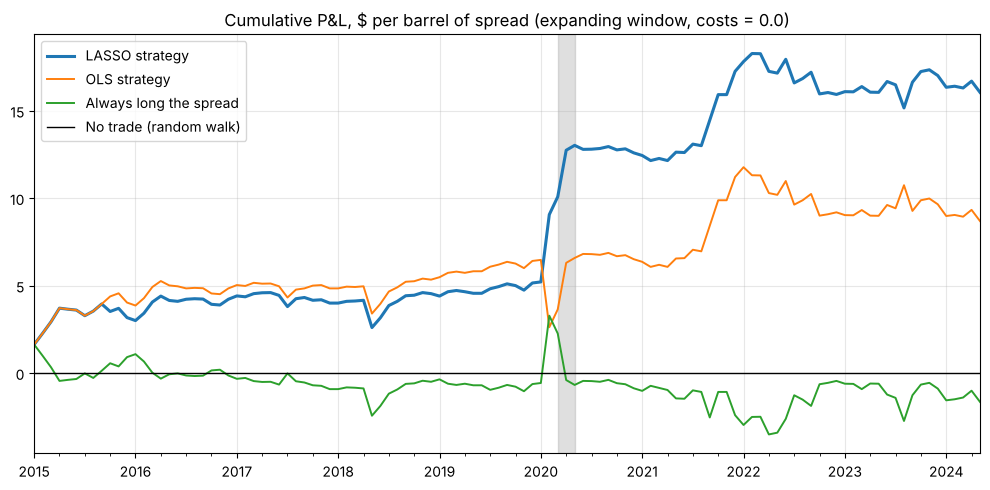

In [47]:
fig, ax = plt.subplots(figsize=(10, 5))
styles = {"LASSO strategy": ("tab:blue", 2.2), "OLS strategy": ("tab:orange", 1.4),
          "Always long the spread": ("tab:green", 1.4), "No trade (random walk)": ("black", 1.0)}
for c, (col, lw) in styles.items():
    ts(pnls[c].cumsum()).plot(ax=ax, label=c, color=col, lw=lw)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-05-31"), color="grey", alpha=0.25)
ax.set_title(f"Cumulative P&L, $ per barrel of spread ({MAIN_WINDOW} window, costs = {TRANSACTION_COST})")
ax.set_xlabel(""); ax.legend(); plt.tight_layout(); plt.show()

### 12.4 Limitations to carry into the report
These are not coded checks; they are the honest caveats a trader should hear, and the seed of the report's limitations section.
- **Contract rolls.** Monthly CL1 and CL2 are the front two contracts at each month-end. When the front contract expires between two month-ends, "CL1" is a different contract, so the measured spread change includes a roll effect that a real position would not earn exactly.
- **Costs and liquidity.** Costs are zero here. A strategy that flips every month pays them every month, and position size is assumed unconstrained.
- **Changing regime.** The spread has changed character over time (Step 3.2), so past patterns may not hold.
- **2020.** A few extreme months can dominate any result (Step 9).
- **Evidence strength.** The brief grades justification and honesty, not beating the market. If the gains over the random walk are not significant (Step 8), the report says so.

---
## Step 13: Summary

One table with the main numbers, for a quick read. (Everything here is already computed above.)

In [48]:
rows = []
for w in results:
    t = eval_all[w]
    for m in ["OLS", "LASSO"]:
        rows.append({"window": w, "model": m, "RMSE (pp)": t.loc[m, "RMSE (pp)"],
                     "RW RMSE (pp)": t.loc["random walk", "RMSE (pp)"],
                     "MAE (pp)": t.loc[m, "MAE (pp)"], "RW MAE (pp)": t.loc["random walk", "MAE (pp)"],
                     "MAPE %": t.loc[m, "MAPE %"],
                     "OOS R2 vs RW": t.loc[m, "OOS R2 vs RW"], "hit rate": t.loc[m, "hit rate"]})
pd.DataFrame(rows).set_index(["window", "model"])

RMSE (pp)  RW RMSE (pp)  MAE (pp)  RW MAE (pp)     MAPE %  OOS R2 vs RW  hit rate
window    model                                                                                   
expanding OLS       2.3680        2.4488    0.9479       0.8647 1,717.3043        0.0649    0.5929
          LASSO     2.3361        2.4488    0.8186       0.8647   616.5440        0.0899    0.6018
rolling   OLS       2.6781        2.4488    1.1933       0.8647   808.6253       -0.1960    0.5487
          LASSO     2.3639        2.4488    0.9056       0.8647   240.4400        0.0681    0.4690

---
## Appendix A: Why the target is the one-month change in the spread

The brief asks which target is most useful to a trader (the CL1 price, CL1 returns, or the CL2 − CL1 spread) and what econometric properties each one has. This table compares the candidates on the **training years only** (1995 to 2014), so the test period stays untouched. It uses the same ADF and KPSS helper as Step 5, and adds two plain measures:

- **lag-1 autocorrelation**: how closely this month's value resembles last month's (1 means it barely moves away from where it was);
- **std per month**: how much the series moves in a typical month.

In [ ]:
target_cands = pd.DataFrame({
    "CL1 price level":         df["CL1"],
    "CL1 monthly log return":  np.log(df["CL1"]).diff(),
    "Spread level":            df["spread"],
    "Spread one-month change": df["spread"].diff(),
}).loc[:TRAIN_END]

target_rows = []
for name in target_cands:
    s = target_cands[name].dropna()
    row = stationarity_row(s, name)
    row["lag-1 autocorrelation"] = s.autocorr(1)
    row["std per month"] = s.std()
    target_rows.append(row)
target_tbl = pd.DataFrame(target_rows).set_index("series")

print(f"CL1 range over the full sample: ${df['CL1'].min():.2f} to ${df['CL1'].max():.2f} per barrel")
target_tbl

CL1 range over the full sample: $11.22 to $140.00 per barrel


,ADF p-value,KPSS p-value,verdict,lag-1 autocorrelation,std per month
series,,,,,
CL1 price level,0.3382,0.0100,unit root,0.9856,32.3716
CL1 monthly log return,0.0000,0.1000,stationary,0.1190,0.0925
Spread level,0.0000,0.0356,unclear,0.8058,0.0196
Spread one-month change,0.0000,0.1000,stationary,-0.1422,0.0122


**Reading the table.**
- **CL1 price level**: a unit root (ADF does not reject, KPSS rejects) and an autocorrelation close to 1. Regressing a trending price on other trending series risks a spurious regression.
- **CL1 monthly return**: stationary, but it carries the full directional risk of oil, and its low autocorrelation means past values say little about the next move.
- **Spread level**: ADF rejects a unit root but KPSS also rejects stationarity, so it is borderline: very persistent, pulled back only slowly by storage and financing costs.
- **Spread one-month change**: clearly stationary on both tests. It is also what a calendar-spread position earns, which is why it is the target (Step 2.3).

The spread is a ratio to CL1, so it stays comparable across a sample in which CL1 ranges from about $11 to $140.